<div dir="rtl" lang="he" xml:lang="he">
<font size=6>עיבוד נתונים - מעבדה ג'</font>

<font size=5> מחברת colab </font>


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.odr import Model, ODR, RealData

In [4]:
file_path = r"/content/ניסוי לייזרים- מדידה 2 (טמפ קבוע זרם לא).xlsx" # Replace with your file path: r"/content/<your file name>.xlsx"
sheet_name = 0 # Replace with your sheet number
data = pd.read_excel(file_path, sheet_name=sheet_name)
data[:5]

,d(cm),P_out(mw,I(A),T©,P_out(mw),P_in(mW),dP_in(mW),dP_out_(mW)
0,32,13.75,1.16,10.9,37.400,851.78,24.59,1.080
1,32,18.20,1.24,10.9,49.504,906.99,26.18,1.431
2,32,22.30,1.33,10.9,60.656,1017.40,29.37,1.753
3,32,26.20,1.42,10.9,71.264,1152.27,33.26,2.059
4,32,29.00,1.51,10.9,78.880,1252.43,36.16,2.278


In [5]:
def choose_columns(columns):
    x = data.iloc[:,columns[0]]
    delta_x = data.iloc[:,columns[1]]
    y = data.iloc[:,columns[2]]
    delta_y = data.iloc[:,columns[3]]
    return x, delta_x, y, delta_y

In [6]:
def function(A, x):
    pass # Define your function. See some examples below.

def linear(A, x):
    return A[1] * x + A[0]

def polynomial(A, x):
    return A[2] * x**2 + A[1] * x + A[0]

def optics(A, x):
    return A[1] * x / (x - A[1]) + A[0]

def exponential(A, x):
    return A[2] * np.exp(A[1] * x) + A[0]

def sinusoidal(A, x):
    return A[3] * np.sin(A[1] * x + A[2]) + A[0]
def ours(A,x):
  return A[1]/x+A[0]

In [7]:
def odr_fit(fit_func, initial_guesses, x, delta_x, y, delta_y):
    model = Model(fit_func)
    odr_data = RealData(x, y, sx=delta_x, sy=delta_y)
    odr = ODR(data=odr_data, model=model, beta0=initial_guesses)
    output = odr.run()

    fit_params = output.beta
    fit_params_error = output.sd_beta
    fit_cov = output.cov_beta
    return fit_params, fit_params_error, fit_cov, output

In [8]:
def calc_stats(x, y, fit_params, output):
    residuals = y - fit_func(fit_params, x)
    degrees_of_freedom = len(x) - len(fit_params)
    chi2 = output.sum_square
    chi2_red = chi2/degrees_of_freedom
    p_val = stats.chi2.sf(chi2, degrees_of_freedom)
    return residuals, degrees_of_freedom, chi2_red, p_val

In [9]:
def print_output(fit_params, fit_params_error, chi2_red, p_val, degrees_of_freedom):
    for i in range(len(fit_params)):
        print(f"a[{i}]: {fit_params[i]} \u00B1 {fit_params_error[i]} ({(abs(fit_params_error[i]/fit_params[i]))*100}% error)")
    print(f"chi squared reduced = {chi2_red:.5f} \u00B1 {np.sqrt(2/degrees_of_freedom)}")
    print(f"p-probability = {p_val:.5e}")
    print(f"DOF = {degrees_of_freedom}")

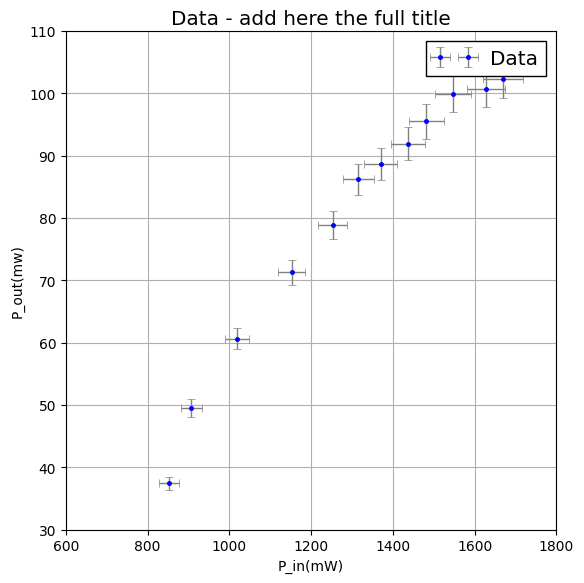

In [10]:
columns = [ 5,6,4,7] # Define the columns indices to represent x, delta x, y, delta y.
x, delta_x, y, delta_y = choose_columns(columns)

plt.close('all')
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
plt.style.use('classic')

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.errorbar(x, y, xerr=delta_x, yerr=delta_y, fmt='.b', label='Data', ecolor='gray') # Change the label if needed


ax.set_title('Data - add here the full title')  # Add here the full title for the fit
ax.set_xlabel(f'{data.columns[columns[0]]}') # Change x-axis label if needed
ax.set_ylabel(f'{data.columns[columns[2]]}') # Change y-axis label if needed

ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

In [11]:
fit_func = linear # Choose your fit function name
initial_guesses = (0, 1) # Define the initial guesses for the parameters in list "A" (make sure they are the same length, and in the same order!)
fit_params, fit_params_error, fit_cov, output = odr_fit(fit_func, initial_guesses, x, delta_x, y, delta_y)
residuals, degrees_of_freedom, chi2_red, p_val = calc_stats(x, y, fit_params, output)
print_output(fit_params, fit_params_error, chi2_red, p_val, degrees_of_freedom)

a[0]: -29.414463656460402 ± 5.834053035942609 (19.83396027233444% error)
a[1]: 0.08441838480434961 ± 0.004880508538650103 (5.781333710614465% error)
chi squared reduced = 1.62162 ± 0.4472135954999579
p-probability = 9.36080e-02
DOF = 10


In [12]:
output.pprint()

Beta: [-29.41446366   0.08441838]
Beta Std Error: [5.83405304e+00 4.88050854e-03]
Beta Covariance: [[ 2.09889755e+01 -1.71025203e-02]
 [-1.71025203e-02  1.46886083e-05]]
Residual Variance: 1.6216215406341745
Inverse Condition #: 1.8938537159403987e-05
Reason(s) for Halting:
  Sum of squares convergence


/tmp/ipykernel_502/431903848.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()


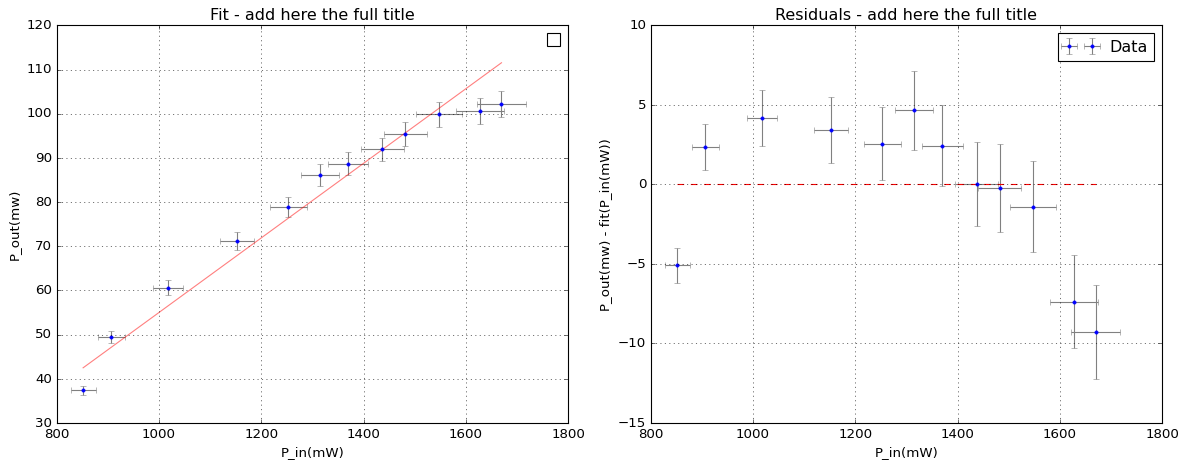

In [13]:
plt.close('all')
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
plt.style.use('classic')

fig.patch.set_facecolor('white')
for ax in axs:
    ax.set_facecolor('white')

x_fit = np.linspace(min(x), max(x), 10*len(x))
y_fit = fit_func(fit_params, x_fit)
axs[0].errorbar(x, y, xerr=delta_x, yerr=delta_y, fmt='.b',  ecolor='gray') # Change the label if needed
axs[0].plot(x_fit, y_fit, c='r', alpha=0.5) # Change the label if needed

# If you want to plot multiple functions, change here the relevant parameters (x, y, xerr, yerr, label). Otherwise, uncomment the 2 next lines:
#axs[0].errorbar(x + 0.2, y + 0.3, xerr=delta_x, yerr=delta_y, fmt='.g', ecolor='gray')
#axs[0].plot(x_fit + 0.2, y_fit + 0.3, label='Fit', c='k', alpha=0.5)

axs[0].set_title('Fit - add here the full title')  # Add here the full title for the fit
axs[0].set_xlabel(f'{data.columns[columns[0]]}') # Change x-axis label if needed
axs[0].set_ylabel(f'{data.columns[columns[2]]}') # Change y-axis label if needed

axs[0].grid(True)
axs[0].legend()

axs[1].errorbar(x, residuals, xerr=delta_x, yerr=delta_y, fmt='.b', label="Data", ecolor='gray')
axs[1].hlines(0, min(x), max(x), colors='r', linestyles='dashed')

axs[1].set_title('Residuals - add here the full title') # Add here the full title for the residuals
axs[1].set_xlabel(f'{data.columns[columns[0]]}') # Change column names if needed
axs[1].set_ylabel(f'{data.columns[columns[2]]} - fit({data.columns[columns[0]]})') # Change column names if needed

axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()